In [6]:
import rasterio

#medium
##L1
# with rasterio.open("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif") as lsrc:

with rasterio.open("/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
     rasterio.open("/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif") as lsrc:
    
##L2
# with rasterio.open("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03.tif") as lsrc:
 
   
    
#low
# with rasterio.open("/media/laura/laura_usb/qgis/calperumResearch/site2_1_DD0011/lidar/sfm_dense/SASMDD0011_dsm_3cm.tif") as msrc, \
#      rasterio.open("/media/laura/Extreme SSD/qgis/calperumResearch/site2_1_DD0011/lidar/cloud2453cf90763afd91_DSM_3cm.tif") as lsrc:
    
    print("📏 MicaSense DSM shape:", msrc.height, "x", msrc.width)
    print("📏 LiDAR DEM shape    :", lsrc.height, "x", lsrc.width)
    print("🧭 MicaSense bounds   :", msrc.bounds)
    print("🧭 LiDAR bounds       :", lsrc.bounds)
    print("📐 MicaSense transform:", msrc.transform)
    print("📐 LiDAR transform    :", lsrc.transform)

📏 MicaSense DSM shape: 14380 x 14314
📏 LiDAR DEM shape    : 15933 x 13234
🧭 MicaSense bounds   : BoundingBox(left=461649.36835590197, bottom=6237319.415841555, right=462078.78835590195, top=6237750.815841556)
🧭 LiDAR bounds       : BoundingBox(left=461661.6499999113, bottom=6237294.869999838, right=462058.66999991133, top=6237772.859999838)
📐 MicaSense transform: | 0.03, 0.00, 461649.37|
| 0.00,-0.03, 6237750.82|
| 0.00, 0.00, 1.00|
📐 LiDAR transform    : | 0.03, 0.00, 461661.65|
| 0.00,-0.03, 6237772.86|
| 0.00, 0.00, 1.00|


In [ ]:
### GOOD: better resampling
import os
import rasterio
from rasterio.warp import reproject, Resampling
import numpy as np

def create_raster_with_reference_shape(
    source_data_path: str, 
    template_grid_path: str, 
    destination_path: str, 
    resampling_method=Resampling.bilinear
):
    """
    Creates a new raster file with the exact shape and grid of a template raster.

    This function reads the pixel values from the source raster and resamples them
    to fit perfectly onto the grid defined by the template raster. The output file
    will have the exact same dimensions (height/width), CRS, and extent as the
    template file. Both input files remain unchanged.

    Args:
        source_data_path (str): Path to the raster providing the pixel values (e.g., LiDAR DSM).
        template_grid_path (str): Path to the raster providing the target grid/shape (e.g., imagery DSM).
        destination_path (str): Path where the new, aligned raster will be saved.
        resampling_method (Resampling, optional): The algorithm for resampling.
            Defaults to Resampling.bilinear.
    """
    print("--- Creating New Raster with Template Shape ---")
    print(f"Source of Data:   '{source_data_path}'")
    print(f"Template for Grid:  '{template_grid_path}'")
    print(f"New Output File:    '{destination_path}'")

    # Ensure the output directory exists.
    output_dir = os.path.dirname(destination_path)
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        print(f"Created output directory: {output_dir}")

    # 1. Open the template file to get its grid definition (profile).
    # This file is ONLY READ FROM, never written to.
    with rasterio.open(template_grid_path) as template_ds:
        template_profile = template_ds.profile
        
    # 2. Open the source data file.
    # This file is also ONLY READ FROM.
    with rasterio.open(source_data_path) as source_ds:
        
        # 3. Define the metadata for our NEW output file.
        # It's a copy of the template's grid, but we'll use the
        # data type (e.g., float32) and nodata value from our source data.
        output_profile = template_profile.copy()
        output_profile.update({
            'dtype': source_ds.profile.get('dtype', 'float32'),
            'nodata': source_ds.nodata
        })

        # 4. Create an empty placeholder array. This array has the exact
        # dimensions of our template raster.
        destination_array = np.empty(
            (template_profile['height'], template_profile['width']), 
            dtype=output_profile['dtype']
        )

        # 5. This is the core step. 'reproject' takes the data from the source,
        # transforms it in memory, and fills our placeholder array.
        reproject(
            source=rasterio.band(source_ds, 1),
            destination=destination_array,
            src_transform=source_ds.transform,
            src_crs=source_ds.crs,
            dst_transform=template_profile['transform'],
            dst_crs=template_profile['crs'],
            resampling=resampling_method
        )
        
        # 6. Save the new array to the destination file with the correct profile.
        with rasterio.open(destination_path, 'w', **output_profile) as dst:
            dst.write(destination_array, 1)

    print(f"\n✅ Success! New raster created at '{destination_path}' with the exact shape of the reference file.")


if __name__ == "__main__":
    # --- Define file paths ---
    #l1
    # lidar_dsm_path = "/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
    lidar_dsm_path = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
    #l2
    # lidar_dsm_path = "/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/SASMDD0001_l2_dsm_03.tif"
    
    # imagery_dsm_path = "/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif"
    imagery_dsm_path = "/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif"
    
    # The final output file path.
    # output_path = "/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif"
    output_path = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif"
    
    # output_path = "/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_l1/SASMDD0001_l2_dsm_03.tif"


    # --- Run the process ---
    if not os.path.exists(lidar_dsm_path):
        print(f"Error: Source data file not found at: {lidar_dsm_path}")
    elif not os.path.exists(imagery_dsm_path):
        print(f"Error: Template grid file not found at: {imagery_dsm_path}")
    else:
        create_raster_with_reference_shape(
            source_data_path=lidar_dsm_path,
            template_grid_path=imagery_dsm_path,
            destination_path=output_path
        )

--- Creating New Raster with Template Shape ---
Source of Data:   '/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif'
Template for Grid:  '/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif'
New Output File:    '/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif'

✅ Success! New raster created at '/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif' with the exact shape of the reference file.


In [3]:
import rasterio

#medium
##L1
# with rasterio.open("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif") as lsrc:

with rasterio.open("/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
     rasterio.open("/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif") as lsrc:
    
##L2
# with rasterio.open("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/media/laura/laura_usb/uas_data/DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03.tif") as lsrc:

# with rasterio.open("/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/data/calperumResearch/site1_1_DD0001/lidar_l2/dsm/crop_to_rgb/SASMDD0001_l2_dsm_03.tif") as lsrc:
   
    
#low
# with rasterio.open("/media/laura/laura_usb/qgis/calperumResearch/site2_1_DD0011/lidar/sfm_dense/SASMDD0011_dsm_3cm.tif") as msrc, \
#      rasterio.open("/media/laura/Extreme SSD/qgis/calperumResearch/site2_1_DD0011/lidar/cloud2453cf90763afd91_DSM_3cm.tif") as lsrc:

#L1
# with rasterio.open("/data/calperumResearch/site2_1_DD0011/imagery/dsm/SASMDD0011_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/data/calperumResearch/site2_1_DD0011/lidar/dsm/crop_to_rgb/SASMDD0011_l1_dsm_03.tif") as lsrc:

#L2  
# with rasterio.open("/data/calperumResearch/site2_1_DD0011/imagery/dsm/SASMDD0011_rgb_dsm_03.tif") as msrc, \
#      rasterio.open("/data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/crop_to_rgb/SASMDD0011_l2_dsm_03.tif") as lsrc:
    
    print("📏 MicaSense DSM shape:", msrc.height, "x", msrc.width)
    print("📏 LiDAR DEM shape    :", lsrc.height, "x", lsrc.width)
    print("🧭 MicaSense bounds   :", msrc.bounds)
    print("🧭 LiDAR bounds       :", lsrc.bounds)
    print("📐 MicaSense transform:", msrc.transform)
    print("📐 LiDAR transform    :", lsrc.transform)

📏 MicaSense DSM shape: 14380 x 14314
📏 LiDAR DEM shape    : 14380 x 14314
🧭 MicaSense bounds   : BoundingBox(left=461649.36835590197, bottom=6237319.415841555, right=462078.78835590195, top=6237750.815841556)
🧭 LiDAR bounds       : BoundingBox(left=461649.36835590197, bottom=6237319.415841555, right=462078.78835590195, top=6237750.815841556)
📐 MicaSense transform: | 0.03, 0.00, 461649.37|
| 0.00,-0.03, 6237750.82|
| 0.00, 0.00, 1.00|
📐 LiDAR transform    : | 0.03, 0.00, 461649.37|
| 0.00,-0.03, 6237750.82|
| 0.00, 0.00, 1.00|


## Before/After Shape Comparison

In [1]:
import rasterio

print("=" * 80)
print("BEFORE/AFTER RASTER SHAPE COMPARISON")
print("=" * 80)

# Site 1, L1 example
lidar_original = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
imagery_template = "/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif"
lidar_resampled = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif"

print("\n📊 BEFORE RESAMPLING:")
with rasterio.open(lidar_original) as src:
    print(f"   LiDAR DSM:    {src.height} × {src.width} pixels")
    print(f"   Bounds:       {src.bounds}")
    print(f"   Transform:    {src.transform}")

with rasterio.open(imagery_template) as src:
    print(f"   Imagery DSM:  {src.height} × {src.width} pixels (target)")
    print(f"   Bounds:       {src.bounds}")
    print(f"   Transform:    {src.transform}")

print("\n📊 AFTER RESAMPLING:")
try:
    with rasterio.open(lidar_resampled) as src:
        print(f"   LiDAR DSM:    {src.height} × {src.width} pixels ✅ MATCHED")
        print(f"   Bounds:       {src.bounds}")
        print(f"   Transform:    {src.transform}")
        
    with rasterio.open(imagery_template) as template, \
         rasterio.open(lidar_resampled) as resampled:
        if (template.height == resampled.height and 
            template.width == resampled.width and
            template.bounds == resampled.bounds):
            print("\n✅ SUCCESS: Shapes and bounds match perfectly!")
        else:
            print("\n⚠️ WARNING: Shapes or bounds don't match!")
            
except FileNotFoundError:
    print("   ⚠️ Resampled file not yet created. Run the resampling cell first.")

print("=" * 80)

BEFORE/AFTER RASTER SHAPE COMPARISON

📊 BEFORE RESAMPLING:
   LiDAR DSM:    15933 × 13234 pixels
   Bounds:       BoundingBox(left=461661.6499999113, bottom=6237294.869999838, right=462058.66999991133, top=6237772.859999838)
   Transform:    | 0.03, 0.00, 461661.65|
| 0.00,-0.03, 6237772.86|
| 0.00, 0.00, 1.00|
   Imagery DSM:  14380 × 14314 pixels (target)
   Bounds:       BoundingBox(left=461649.36835590197, bottom=6237319.415841555, right=462078.78835590195, top=6237750.815841556)
   Transform:    | 0.03, 0.00, 461649.37|
| 0.00,-0.03, 6237750.82|
| 0.00, 0.00, 1.00|

📊 AFTER RESAMPLING:
   LiDAR DSM:    14380 × 14314 pixels ✅ MATCHED
   Bounds:       BoundingBox(left=461649.36835590197, bottom=6237319.415841555, right=462078.78835590195, top=6237750.815841556)
   Transform:    | 0.03, 0.00, 461649.37|
| 0.00,-0.03, 6237750.82|
| 0.00, 0.00, 1.00|

✅ SUCCESS: Shapes and bounds match perfectly!


## Visual Comparison

/tmp/ipykernel_2413864/1652736015.py:53: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


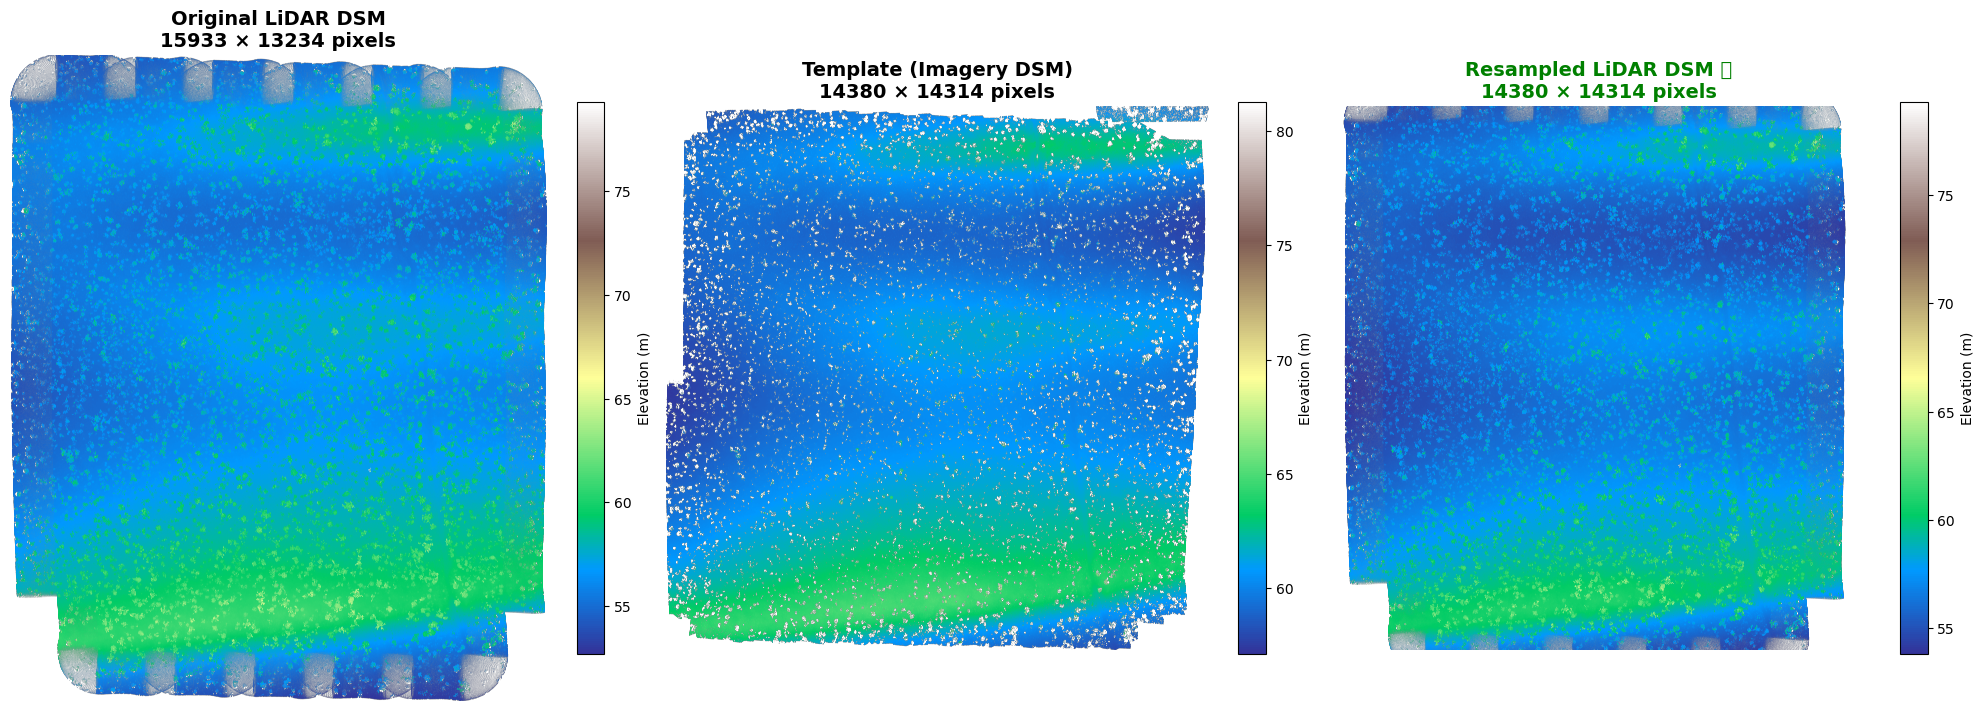


💡 The resampled DSM should have the exact same dimensions as the template.


In [5]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

# File paths
lidar_original = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
imagery_template = "/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif"
lidar_resampled = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif"

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1. Original LiDAR DSM
with rasterio.open(lidar_original) as src:
    data = src.read(1)
    data = np.ma.masked_equal(data, src.nodata) if src.nodata else data
    
    im1 = axes[0].imshow(data, cmap='terrain')
    axes[0].set_title(f'Original LiDAR DSM\n{src.height} × {src.width} pixels', 
                      fontsize=14, fontweight='bold')
    plt.colorbar(im1, ax=axes[0], label='Elevation (m)', fraction=0.046)
    axes[0].axis('off')

# 2. Template (Imagery DSM)
with rasterio.open(imagery_template) as src:
    data = src.read(1)
    data = np.ma.masked_equal(data, src.nodata) if src.nodata else data
    
    im2 = axes[1].imshow(data, cmap='terrain')
    axes[1].set_title(f'Template (Imagery DSM)\n{src.height} × {src.width} pixels', 
                      fontsize=14, fontweight='bold')
    plt.colorbar(im2, ax=axes[1], label='Elevation (m)', fraction=0.046)
    axes[1].axis('off')

# 3. Resampled LiDAR DSM
try:
    with rasterio.open(lidar_resampled) as src:
        data = src.read(1)
        data = np.ma.masked_equal(data, src.nodata) if src.nodata else data
        
        im3 = axes[2].imshow(data, cmap='terrain')
        axes[2].set_title(f'Resampled LiDAR DSM ✅\n{src.height} × {src.width} pixels', 
                          fontsize=14, fontweight='bold', color='green')
        plt.colorbar(im3, ax=axes[2], label='Elevation (m)', fraction=0.046)
        axes[2].axis('off')
except FileNotFoundError:
    axes[2].text(0.5, 0.5, '⚠️ Resampled file not found\nRun resampling cell first', 
                ha='center', va='center', transform=axes[2].transAxes, 
                fontsize=14, color='red')
    axes[2].set_title('Resampled LiDAR DSM', fontsize=14, fontweight='bold')
    axes[2].axis('off')

plt.tight_layout()
plt.show()

print("\n💡 The resampled DSM should have the exact same dimensions as the template.")